# Median House Value with one-hidden layer neural networks (Classification)
### Keras using callbacks
Base Code by [D. Manrique](https://orcid.org/0000-0002-0792-4156)

## UPM-MUIA Neural Networks and Reinforcent Learning
### Passenger Satisfaction Practical Assignment
Group 9

Author: Luis Carles Dura

## Import libraries



In [1]:
%pip install pandas scikit-learn matplotlib seaborn bokeh tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Tensorflow and tf.keras
import tensorflow as tf
from tensorflow import keras
print("Tensorflow version:",tf.__version__)
print("Keras version:",keras.__version__)
print(tf.config.list_physical_devices('GPU'))

# Helper libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

2026-11-13 17:42:37.349026: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Tensorflow version: 2.20.0
Keras version: 3.12.4
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Callbacks

In [3]:
from tensorflow.keras.callbacks import Callback
from tqdm import tqdm

class TqdmProgressCallback(Callback):
    def __init__(self, epochs, verbose=0):
        super(TqdmProgressCallback, self).__init__()
        self.epochs = epochs
        self.verbose = verbose
        
    def on_train_begin(self, logs=None):
        self.epoch_bar = tqdm(total=self.epochs, desc='Epochs', position=0)
       
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_bar.update(1)
        
    def on_train_end(self, logs=None):
        self.epoch_bar.close()

In [4]:
class StopWhenValLossBelow(Callback):
    def __init__(self, threshold):
        super().__init__()
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        val_loss = logs.get('val_loss')
        if val_loss is not None and val_loss < self.threshold:
            print(f"\nStopping training: val_loss has reached {val_loss:.4f}, which is below the threshold of {self.threshold}")
            self.model.stop_training = True

In [5]:
class StopTrainingAtEpoch(Callback):
    def __init__(self, stop_epoch=5):
        super().__init__()
        self.stop_epoch = stop_epoch

    def on_epoch_end(self, epoch, logs=None):
        if epoch == self.stop_epoch:
            print(f"\nStopping training at epoch {epoch}")
            self.model.stop_training = True

## Load data

In [6]:
from pathlib import Path
#from google.colab import drive

# 2. Definir las rutas del proyecto
#PROJECT_DIR = Path("/content/drive/MyDrive/ImageRecognition")
PROJECT_DIR = Path("../")

DATASET_DIR = PROJECT_DIR / "kaggle_satisfaction"

ATT_FILE = DATASET_DIR / "SatisfactionPreparedCleanAttributes.csv"
LABEL_FILE = DATASET_DIR / "SatisfactionBinaryEncodedClasses.csv"

# 3. Comprobar que las rutas existen
print("Proyecto:", PROJECT_DIR)
print("Existe el proyecto:", PROJECT_DIR.is_dir())

print("\nDataset:", DATASET_DIR)
print("Existe el dataset:", DATASET_DIR.is_dir())

print("\nAttributes:", ATT_FILE)
print("Existe el fichero de Atributos:", ATT_FILE.is_file())

print("\nClasses:", LABEL_FILE)
print("Existe el fichero de Atributos:", LABEL_FILE.is_file())

# 4. Crear training, validation and test subsets
TRAIN_RATE=0.8 # 80% of the entire dataset is for training purposes

attributes = pd.read_csv(ATT_FILE)
label = pd.read_csv(LABEL_FILE)
n_instances = attributes.shape[0]

n_train = int(n_instances*TRAIN_RATE)
n_dev = int((n_instances-n_train)/2)
n_test = n_instances-n_train-n_dev

# Conjunto de Entrenamiento 80%
x_train = attributes.values[:n_train]
t_train = label.values[:n_train]

# Conjunto de Validacion 10%
x_dev = attributes.values[n_train:n_train+n_dev]
t_dev = label.values[n_train:n_train+n_dev]

# Conjunto de Test
x_test = attributes.values[n_train+n_dev:]
t_test = label.values[n_train+n_dev:]

print("\nTraining:"  , x_train.shape, t_train.shape, "\n", pd.Series(t_train.flatten()).value_counts(normalize=True))
print("\nValidation:", x_dev.shape  , t_dev.shape  , "\n", pd.Series(t_dev.flatten()).value_counts(normalize=True))
print("\nTest:"      , x_test.shape , t_test.shape , "\n", pd.Series(t_test.flatten()).value_counts(normalize=True))

Proyecto: ..
Existe el proyecto: True

Dataset: ../kaggle_satisfaction
Existe el dataset: True

Attributes: ../kaggle_satisfaction/SatisfactionPreparedCleanAttributes.csv
Existe el fichero de Atributos: True

Classes: ../kaggle_satisfaction/SatisfactionBinaryEncodedClasses.csv
Existe el fichero de Atributos: True

Training: (20714, 27) (20714, 1) 
 0    0.560297
1    0.439703
Name: proportion, dtype: float64

Validation: (2589, 27) (2589, 1) 
 0    0.561221
1    0.438779
Name: proportion, dtype: float64

Test: (2590, 27) (2590, 1) 
 0    0.567181
1    0.432819
Name: proportion, dtype: float64


## Initialize variables

In [7]:
INPUTS = x_train.shape[1]
OUTPUTS = t_train.shape[1]
NUM_TRAINING_EXAMPLES = int(round(x_train.shape[0]/1))
NUM_DEV_EXAMPLES = int (round (x_dev.shape[0]/1))

In [8]:
x_train[:5]

array([[0.3974359 , 0.17661488, 0.6       , 0.8       , 0.6       ,
        0.5       , 0.8       , 0.6       , 0.        , 0.8       ,
        0.8       , 1.        , 1.        , 0.5       , 1.        ,
        0.8       , 0.        , 0.        , 0.        , 1.        ,
        0.        , 1.        , 0.        , 1.        , 0.        ,
        1.        , 0.        ],
       [0.47435897, 0.11092941, 0.8       , 0.4       , 0.4       ,
        0.25      , 0.8       , 0.8       , 0.75      , 0.8       ,
        0.6       , 0.6       , 0.25      , 1.        , 0.6       ,
        0.8       , 0.        , 0.3       , 0.        , 1.        ,
        0.        , 1.        , 1.        , 0.        , 0.        ,
        1.        , 0.        ],
       [0.78205128, 0.26246934, 0.6       , 0.8       , 0.6       ,
        0.5       , 0.4       , 0.6       , 0.25      , 0.4       ,
        1.        , 0.6       , 1.        , 0.5       , 0.8       ,
        0.4       , 0.16666667, 0.16666667, 0.    

In [9]:
t_train[:5]

array([[0],
       [1],
       [0],
       [1],
       [1]])

In [10]:
x_dev[:5]

array([[0.57692308, 0.86399564, 0.8       , 0.8       , 0.8       ,
        0.75      , 0.4       , 0.8       , 1.        , 0.8       ,
        0.8       , 0.8       , 0.75      , 1.        , 0.8       ,
        0.8       , 0.        , 0.        , 0.        , 1.        ,
        0.        , 1.        , 1.        , 0.        , 1.        ,
        0.        , 0.        ],
       [0.46153846, 0.22621968, 1.        , 1.        , 0.6       ,
        1.        , 0.6       , 0.8       , 1.        , 1.        ,
        1.        , 1.        , 1.        , 0.5       , 1.        ,
        0.8       , 0.        , 0.36666667, 0.        , 1.        ,
        0.        , 1.        , 1.        , 0.        , 1.        ,
        0.        , 0.        ],
       [0.74358974, 0.08340147, 0.2       , 1.        , 0.2       ,
        0.75      , 0.6       , 0.8       , 0.75      , 0.4       ,
        0.4       , 0.2       , 0.25      , 0.75      , 0.4       ,
        0.8       , 0.9       , 1.        , 1.    

In [11]:
t_dev[:5]

array([[1],
       [1],
       [0],
       [0],
       [0]])

## Set hyperparameters

In [135]:
n_epochs = 1000
lr = 1e-3
batch_size = 256

## Build the model


In [136]:
# Sequential
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Flatten, Add, Input
from tensorflow.keras.models import Model

# Regularization, Initialization, LeakyReLU
from tensorflow.keras.regularizers import l1,l2
from tensorflow.keras.layers import LeakyReLU, Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal

# ffNN Model 
print('Load model')

model = Sequential()

# Input
model.add(Input(shape=(INPUTS,)))

# 1 Capa 512 neurona
model.add(Dense(512, activation="relu"))
#model.add(BatchNormalization())
#model.add(LeakyReLU(negative_slope=0.01))
model.add(Dropout(0.3))

# Output - 2 Categorias: Satisfecho / Insatisfecho
model.add(Dense(OUTPUTS, activation="sigmoid"))

model.summary()

Load model


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_68 (Dense)                │ (None, 512)            │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_69 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849 (58.00 KB)

 Trainable params: 14,849 (58.00 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the model

In [137]:
# OPTIMIZER, LOSS FUNCTION, METRICS
from tensorflow.keras.optimizers import Adam, SGD, RMSprop, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay
import math

#CosineDecay
#lr_schedule = CosineDecay(initial_learning_rate=lr, decay_steps=n_epochs*math.ceil(NUM_TRAINING_EXAMPLES/batch_size), alpha=1/30)

# Learning rate is changed to 0.001 -> Adam
opt = Adam(learning_rate=lr, beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)
#opt = SGD(learning_rate=lr, momentum=0.9, clipnorm=1.0)
#opt = RMSprop(learning_rate=lr, rho=0.9, momentum=0.0, epsilon=1e-8, clipnorm=1.0)
#opt = AdamW(learning_rate=lr, weight_decay=1e-4)
loss_function = tf.keras.losses.BinaryCrossentropy() #(label_smoothing=0.05)

model.compile(optimizer=opt, loss=loss_function, metrics=['binary_accuracy'])

## Train the model with Mini-Batch Gradient Descent



In [138]:
from tensorflow.keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# tqdm Callbacks
tqdm_callback = TqdmProgressCallback(epochs=n_epochs)
stopWhenValLossBelow_callback = StopWhenValLossBelow(threshold=0.65)
stopTrainingAtEpoch_callback = StopTrainingAtEpoch(stop_epoch=5)

# CV Callbacks
model_checkpoint = ModelCheckpoint('model.keras', monitor='val_binary_accuracy', verbose=0, save_best_only=True)
reduce_lr = ReduceLROnPlateau('val_binary_accuracy', factor=0.5, patience=80, min_lr=1e-6, verbose=1)
early_stop = EarlyStopping(monitor='val_binary_accuracy', patience=240, restore_best_weights=True,verbose=1)
terminate = TerminateOnNaN()

#callbacks=[tqdm_callback, early_stop] #earlystopWhenValLossBelow_callback, stopTrainingAtEpoch_callback
callbacks = [tqdm_callback, model_checkpoint, early_stop] 

In [139]:
import time
inicio = time.time()

h = model.fit(x_train, t_train, batch_size=batch_size, epochs=n_epochs, verbose=0, validation_data=(x_dev, t_dev),
              callbacks=callbacks)

# Best validation model
best_idx = int(np.argmax(h.history['val_binary_accuracy']))
best_value = np.max(h.history['val_binary_accuracy'])
print('Best validation model: epoch ' + str(best_idx+1), ' - val_binary_accuracy ' + str(best_value))

fin = time.time()
print(f"Tiempo de ejecución: {fin - inicio:.5f} segundos")

Epochs:  67%|███████████████████████████████████████████████▍                       | 669/1000 [05:57<02:56,  1.87it/s]

Epoch 669: early stopping
Restoring model weights from the end of the best epoch: 429.
Best validation model: epoch 429  - val_binary_accuracy 0.9656237959861755
Tiempo de ejecución: 357.81309 segundos


## Get the results


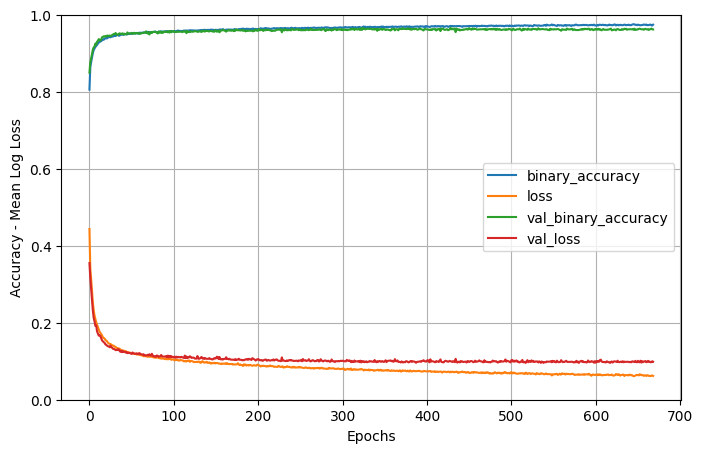

In [140]:
results=pd.DataFrame(h.history)
results.plot(figsize=(8, 5))
plt.grid(True)
plt.xlabel ("Epochs")
plt.ylabel ("Accuracy - Mean Log Loss")
plt.gca().set_ylim(0.0, 1) # set the vertical range to [0.4,1]
plt.show()

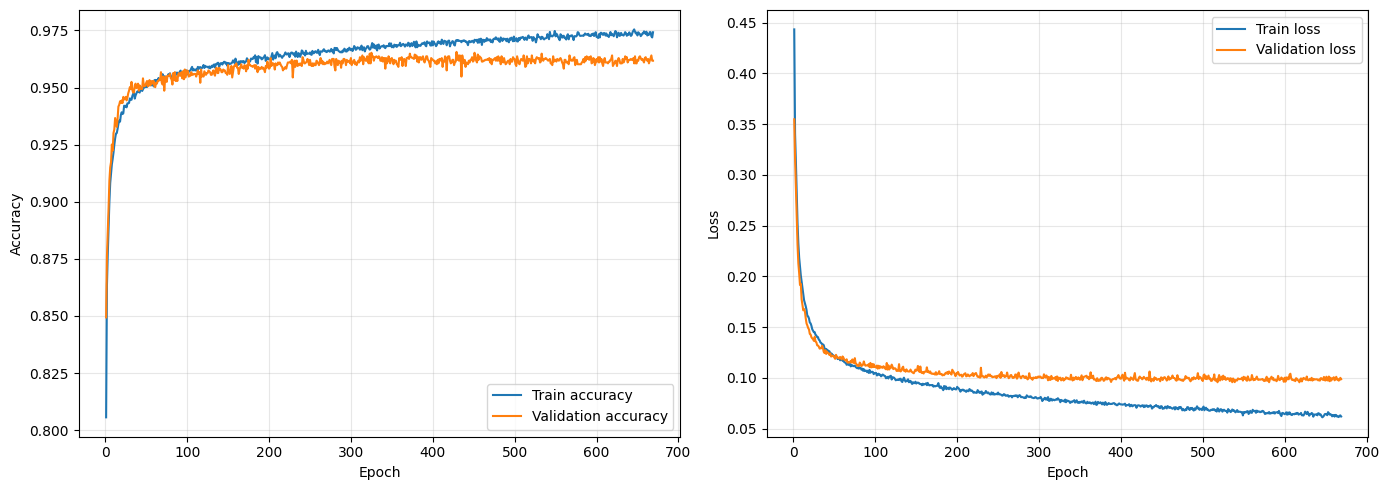

In [141]:
x_epochs = range(1, len(h.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(x_epochs, h.history["binary_accuracy"], label="Train accuracy")
axes[0].plot(x_epochs, h.history["val_binary_accuracy"], label="Validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Loss
axes[1].plot(x_epochs, h.history["loss"], label="Train loss")
axes[1].plot(x_epochs, h.history["val_loss"], label="Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Validation (development) set

In [142]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

dev_predictions = model.predict(x_dev)

dev_rounded_predictions = (dev_predictions >= 0.5).astype(int)

# Accuracy
accuracy = accuracy_score(t_dev, dev_rounded_predictions)

# Recall
recall = recall_score(t_dev, dev_rounded_predictions)

# Precision
precision = precision_score(t_dev, dev_rounded_predictions)

# F1 Score
f1 = f1_score(t_dev, dev_rounded_predictions)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1 Score:  {f1:.4f}")

81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Accuracy:  0.9656
Recall:    0.9613
Precision: 0.9604
F1 Score:  0.9608


#### Confusion Matrix

In [143]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(
    t_dev,
    dev_rounded_predictions
))

print(classification_report(
    t_dev,
    dev_rounded_predictions,
    target_names=["Unsatisfied", "Satisfied"]
))

[[1408   45]
 [  44 1092]]
              precision    recall  f1-score   support

 Unsatisfied       0.97      0.97      0.97      1453
   Satisfied       0.96      0.96      0.96      1136

    accuracy                           0.97      2589
   macro avg       0.97      0.97      0.97      2589
weighted avg       0.97      0.97      0.97      2589



## Test (final) test set

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_predictions = model.predict(x_test)

test_rounded_predictions = (test_predictions >= 0.5).astype(int)

# Accuracy
f_accuracy = accuracy_score(t_test, test_rounded_predictions)

# Precision
f_precision = precision_score(t_test, test_rounded_predictions)

# Recall
f_recall = recall_score(t_test, test_rounded_predictions)

# F1 Score
f_f1 = f1_score(t_test, test_rounded_predictions)

print(f"Accuracy:  {f_accuracy:.4f}")
print(f"Precision: {f_precision:.4f}")
print(f"Recall:    {f_recall:.4f}")
print(f"F1 Score:  {f_f1:.4f}")